# 02 · Exploratory Data Analysis

**Longevity Hook Lab, Part A**: *What makes a YouTube Short beat its channel's median views?*

Input: `data/shorts.csv` (from notebook 01): 2,740 Shorts from 11 health/longevity channels, label `beat` = views above the median of the 31 Shorts the channel posted around the same time (see notebook 01, section 4).

Questions for this notebook:
1. What do the data look like (types, missing values, distributions, outliers)?
2. Which simple title and timing patterns line up with beating the median?
3. Is there anything that could mislead the model (e.g. video age)?

**How to read the beat-rate charts:** each bar is the share of Shorts in that group that beat their neighbours' median. The grey dashed line is the overall beat-rate (just under 50%): "no better than average". Thin black lines are 95% confidence intervals: if a bar's interval crosses the line, the difference could easily be chance.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

DATA = Path("../data")
ASSETS = Path("../images")
ASSETS.mkdir(exist_ok=True)

ACCENT = "#2a78d6"   # single-series colour
REF = "#8a8984"      # reference line
sns.set_theme(style="whitegrid", rc={"grid.color": "#e6e5e0", "axes.edgecolor": "#c3c2b7"})

shorts = pd.read_csv(DATA / "shorts.csv", parse_dates=["published_at"])
BASE_RATE = shorts["beat"].mean()
print(shorts.shape, "overall beat-rate:", round(BASE_RATE, 3))
shorts.head(3)

(2740, 14) overall beat-rate: 0.48


,video_id,creator,handle,channel_type,title,published_at,age_days,duration_sec,views,likes,comments,neighbour_median_views,views_vs_neighbours,beat
0,W5zqC5cYcS0,Andrew Huberman,@hubermanlab,main,How Tone of Voice Shapes Emotional State of Li...,2023-11-14 21:36:41+00:00,1073,58,4227301.0,223273.0,3088.0,349725.0,12.087500,1
1,wG3UFHR1o48,Andrew Huberman,@hubermanlab,main,How to Stop Hiccups Using a Science-Supported ...,2023-11-27 23:29:57+00:00,1060,57,1157347.0,38502.0,1687.0,306463.0,3.776466,1
2,CVh3_8e5u8I,Andrew Huberman,@hubermanlab,main,Cold & Flu: When Are You Most Contagious?,2024-01-08 17:00:45+00:00,1018,60,500902.0,20344.0,418.0,270527.5,1.851575,1


## 1. Data types and missing values

In [2]:
shorts.info()

<class 'pandas.DataFrame'>
RangeIndex: 2740 entries, 0 to 2739
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype              
---  ------                  --------------  -----              
 0   video_id                2740 non-null   str                
 1   creator                 2740 non-null   str                
 2   handle                  2740 non-null   str                
 3   channel_type            2740 non-null   str                
 4   title                   2740 non-null   str                
 5   published_at            2740 non-null   datetime64[us, UTC]
 6   age_days                2740 non-null   int64              
 7   duration_sec            2740 non-null   int64              
 8   views                   2740 non-null   float64            
 9   likes                   2730 non-null   float64            
 10  comments                2740 non-null   float64            
 11  neighbour_median_views  2740 non-null   float64       

In [3]:
shorts.isna().sum()[lambda s: s > 0]

likes    10
dtype: int64

Only `likes` / `comments` have gaps (some creators hide like counts). They are post-publish numbers we won't model on, so no imputation is needed.

In [4]:
shorts[["duration_sec", "age_days", "views", "views_vs_neighbours"]].describe().round(1)

,duration_sec,age_days,views,views_vs_neighbours
count,2740.0,2740.0,2740.0,2740.0
mean,58.3,300.2,209838.9,2.0
std,29.9,225.3,685495.7,14.5
min,4.0,14.0,224.0,0.1
25%,38.0,123.0,5799.2,0.7
50%,54.0,263.5,21377.5,1.0
75%,71.0,436.0,117389.2,1.6
max,180.0,4266.0,14150116.0,738.9


## 2. Views per channel

Views are extremely skewed, so they're plotted on a log scale. Channel medians differ by more than 200×, which is why the label compares each Short only with Shorts from its own channel.

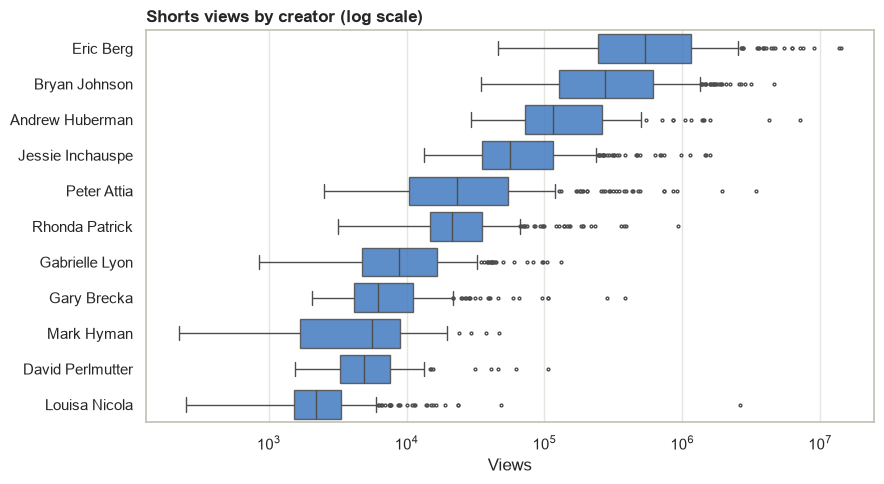

In [5]:
order = shorts.groupby("creator")["views"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=shorts, y="creator", x="views", order=order, color=ACCENT,
            fliersize=2, linewidth=1, boxprops={"alpha": 0.85}, ax=ax)
ax.set_xscale("log")
ax.set_title("Shorts views by creator (log scale)", loc="left", fontweight="bold")
ax.set_xlabel("Views")
ax.set_ylabel("")
plt.tight_layout()
fig.savefig(ASSETS / "views_by_creator.png", dpi=150)
plt.show()

## 3. Outliers: viral Shorts

`views_vs_neighbours` shows how far each Short is from its neighbours' typical result. A few Shorts get 10–100× the median. They're real (that's what virality looks like), so we **keep** them; the binary label means one huge hit counts the same as a small win, so outliers can't dominate the model.

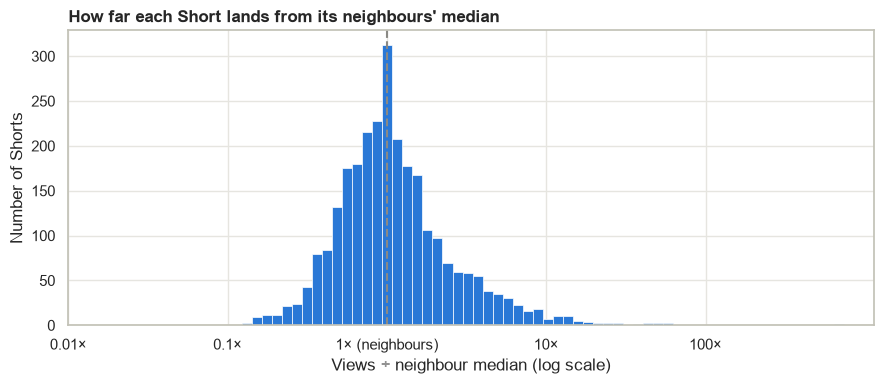

Shorts with ≥ 10× neighbour median: 48


In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(np.log10(shorts["views_vs_neighbours"]), bins=60, color=ACCENT, edgecolor="white", linewidth=0.5)
ax.axvline(0, color=REF, linestyle="--", linewidth=1.5)
ax.set_xticks([-2, -1, 0, 1, 2], ["0.01×", "0.1×", "1× (neighbours)", "10×", "100×"])
ax.set_title("How far each Short lands from its neighbours' median", loc="left", fontweight="bold")
ax.set_xlabel("Views ÷ neighbour median (log scale)")
ax.set_ylabel("Number of Shorts")
plt.tight_layout()
plt.show()

print("Shorts with ≥ 10× neighbour median:", (shorts["views_vs_neighbours"] >= 10).sum())

In [7]:
# The 10 biggest over-performers
shorts.nlargest(10, "views_vs_neighbours")[["creator", "title", "views", "views_vs_neighbours"]].round(1)

,creator,title,views,views_vs_neighbours
1904,Louisa Nicola,Dr. Mike's Unfiltered Truth About His Surgery ...,2626791.0,738.9
22,Andrew Huberman,Is It Safe to Microwave Plastic Containers?,7159866.0,61.0
1208,Gary Brecka,Is Mold Wrecking Your Health?,284340.0,58.7
1124,Gary Brecka,The Muscle-Building Mistake Everyone Makes,385948.0,53.3
2177,Peter Attia,How much time does Tadej Pogačar spend trainin...,3444701.0,47.4
2225,Peter Attia,The Leading Causes of Death - The 4 Horsemen o...,910232.0,45.5
2288,Peter Attia,How Fasting Can Make Chemotherapy More Effecti...,430494.0,42.2
2604,Rhonda Patrick,My top 5 supplements,936072.0,36.4
591,Eric Berg,The #1 MOST Dangerous Carbohydrate in the World!,14150116.0,29.3
723,Eric Berg,The #1 Best Remedy to Get Rid of Tartar,9069253.0,27.9


## 4. Helper: beat-rate bar chart

One function for every comparison below, so all charts read the same way.

In [8]:
def beat_rate_chart(df, column, title, order=None, xlabel=None, min_n=20, filename=None):
    """Bar chart of beat-rate per group, with 95% CI and n under each bar."""
    stats = df.groupby(column, observed=True)["beat"].agg(["mean", "size"])
    stats = stats[stats["size"] >= min_n]
    if order is not None:
        stats = stats.reindex([o for o in order if o in stats.index])
    ci = 1.96 * np.sqrt(stats["mean"] * (1 - stats["mean"]) / stats["size"])

    fig, ax = plt.subplots(figsize=(max(5, 0.75 * len(stats) + 2), 4))
    x = np.arange(len(stats))
    ax.bar(x, stats["mean"], width=0.6, color=ACCENT)
    ax.errorbar(x, stats["mean"], yerr=ci, fmt="none", ecolor="#3a3a38", elinewidth=1, capsize=3)
    ax.axhline(BASE_RATE, color=REF, linestyle="--", linewidth=1.5)
    ax.set_xticks(x, [f"{i}\nn={n}" for i, n in zip(stats.index, stats["size"])], fontsize=9)
    ax.set_ylim(0.2, 0.8)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_ylabel("Beat-rate")
    ax.set_xlabel(xlabel or "")
    ax.set_title(title, loc="left", fontweight="bold")
    plt.tight_layout()
    if filename:
        fig.savefig(ASSETS / filename, dpi=150)
    plt.show()
    return stats.assign(ci=ci).round(3)

## 5. Title patterns

Quick, simple title flags (the full feature set is built in notebook 03).

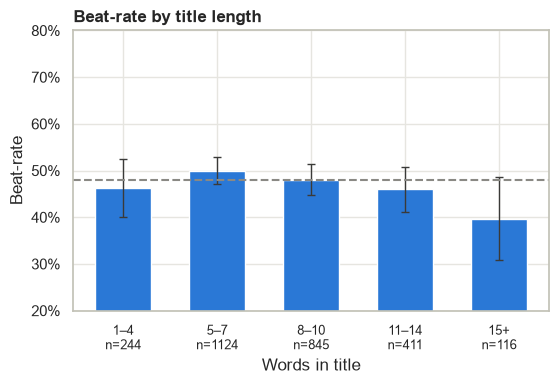

,mean,size,ci
title_length,,,
1–4,0.463,244,0.063
5–7,0.500,1124,0.029
8–10,0.480,845,0.034
11–14,0.460,411,0.048
15+,0.397,116,0.089


In [9]:
shorts["title_words"] = shorts["title"].str.split().str.len()
shorts["title_length"] = pd.cut(shorts["title_words"], bins=[0, 4, 7, 10, 14, 100],
                                labels=["1–4", "5–7", "8–10", "11–14", "15+"])

beat_rate_chart(shorts, "title_length", "Beat-rate by title length", xlabel="Words in title",
                filename="beat_rate_title_length.png")

In [10]:
flags = {
    "question mark": shorts["title"].str.contains(r"\?"),
    "number": shorts["title"].str.contains(r"\d"),
    "'you' / 'your'": shorts["title"].str.contains(r"\byour?\b", case=False),
    "hashtag": shorts["title"].str.contains("#"),
    "emoji": shorts["title"].str.contains(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]"),
    "ALL-CAPS word": shorts["title"].str.contains(r"\b[A-Z]{3,}\b"),
}

flag_table = pd.DataFrame({
    name: {
        "share_of_titles": mask.mean(),
        "beat_rate_with": shorts.loc[mask, "beat"].mean(),
        "beat_rate_without": shorts.loc[~mask, "beat"].mean(),
        "n_with": mask.sum(),
    }
    for name, mask in flags.items()
}).T
flag_table["difference"] = flag_table["beat_rate_with"] - flag_table["beat_rate_without"]
flag_table.sort_values("difference").round(3)

,share_of_titles,beat_rate_with,beat_rate_without,n_with,difference
question mark,0.186,0.448,0.488,511.0,-0.040
ALL-CAPS word,0.204,0.472,0.482,559.0,-0.010
emoji,0.077,0.483,0.480,211.0,0.003
'you' / 'your',0.327,0.484,0.479,897.0,0.005
hashtag,0.064,0.500,0.479,174.0,0.021
number,0.193,0.538,0.467,530.0,0.071


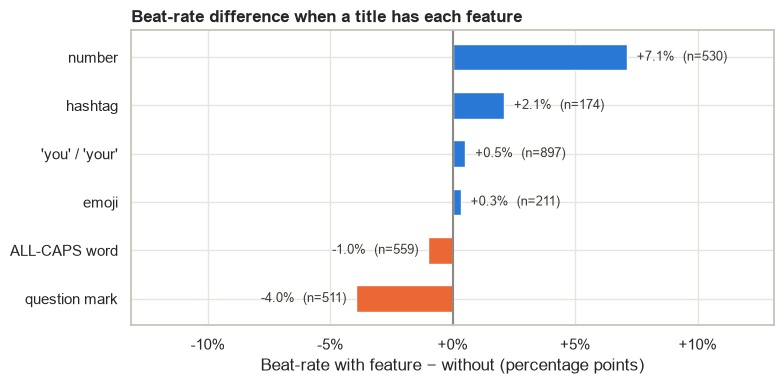

In [11]:
ft = flag_table[flag_table["n_with"] >= 20].sort_values("difference")

fig, ax = plt.subplots(figsize=(8, 4))
colors = [ACCENT if d >= 0 else "#eb6834" for d in ft["difference"]]
ax.barh(ft.index, ft["difference"], color=colors, height=0.55)
ax.axvline(0, color=REF, linewidth=1.5)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
for y, (d, n) in enumerate(zip(ft["difference"], ft["n_with"])):
    ax.text(d + (0.004 if d >= 0 else -0.004), y, f"{d:+.1%}  (n={int(n)})",
            va="center", ha="left" if d >= 0 else "right", fontsize=9, color="#3a3a38")
ax.set_title("Beat-rate difference when a title has each feature", loc="left", fontweight="bold")
ax.set_xlabel("Beat-rate with feature − without (percentage points)")
lim = max(0.12, ft["difference"].abs().max() + 0.06)
ax.set_xlim(-lim, lim)
plt.tight_layout()
fig.savefig(ASSETS / "title_flags.png", dpi=150)
plt.show()

## 6. Timing

Publish times are converted to **US Eastern** time, because most of these creators are US-based. That's an assumption; a few may post from other time zones.

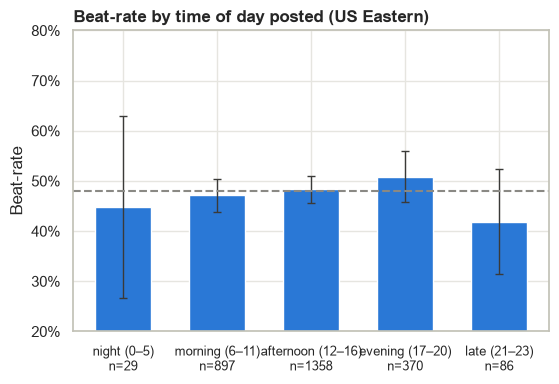

,mean,size,ci
hour_block,,,
night (0–5),0.448,29,0.181
morning (6–11),0.472,897,0.033
afternoon (12–16),0.483,1358,0.027
evening (17–20),0.508,370,0.051
late (21–23),0.419,86,0.104


In [12]:
local = shorts["published_at"].dt.tz_convert("America/New_York")
shorts["publish_hour"] = local.dt.hour
shorts["publish_weekday"] = local.dt.day_name().str[:3]
shorts["hour_block"] = pd.cut(shorts["publish_hour"], bins=[-1, 5, 11, 16, 20, 23],
                              labels=["night (0–5)", "morning (6–11)", "afternoon (12–16)",
                                      "evening (17–20)", "late (21–23)"])

beat_rate_chart(shorts, "hour_block", "Beat-rate by time of day posted (US Eastern)",
                filename="beat_rate_hour.png")

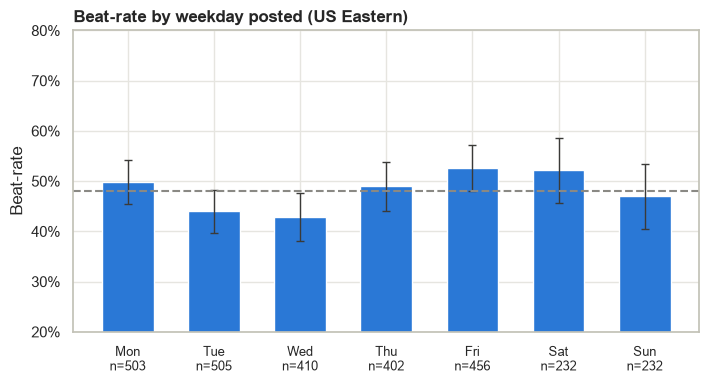

,mean,size,ci
publish_weekday,,,
Mon,0.499,503,0.044
Tue,0.440,505,0.043
Wed,0.429,410,0.048
Thu,0.490,402,0.049
Fri,0.526,456,0.046
Sat,0.522,232,0.064
Sun,0.470,232,0.064


In [13]:
beat_rate_chart(shorts, "publish_weekday", "Beat-rate by weekday posted (US Eastern)",
                order=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])

## 7. Duration

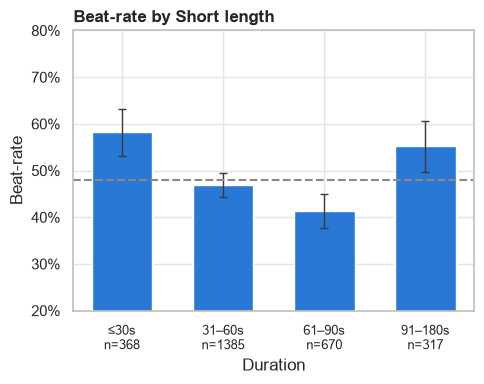

,mean,size,ci
duration_bucket,,,
≤30s,0.582,368,0.050
31–60s,0.469,1385,0.026
61–90s,0.413,670,0.037
91–180s,0.552,317,0.055


In [14]:
shorts["duration_bucket"] = pd.cut(shorts["duration_sec"], bins=[0, 30, 60, 90, 180],
                                   labels=["≤30s", "31–60s", "61–90s", "91–180s"])
beat_rate_chart(shorts, "duration_bucket", "Beat-rate by Short length", xlabel="Duration",
                filename="beat_rate_duration.png")

In [15]:
# Do creators differ in typical length? (could make duration a creator proxy)
shorts.groupby("creator")["duration_sec"].median().sort_values()

creator
Bryan Johnson       46.0
Gary Brecka         48.0
Mark Hyman          50.0
Eric Berg           51.0
Rhonda Patrick      51.0
Jessie Inchauspe    52.0
Louisa Nicola       52.0
Gabrielle Lyon      53.5
Andrew Huberman     59.0
David Perlmutter    60.0
Peter Attia         88.0
Name: duration_sec, dtype: float64

## 8. Risk check: video age

Views are a single snapshot. With a simple channel-median label, Shorts 14–60 days old beat the median only 33% of the time, and some channels showed strong growth/decline trends; that's why notebook 01 switched to the neighbour label. This section checks that the fix worked: beat-rate should now be roughly flat across ages, overall and within each creator.

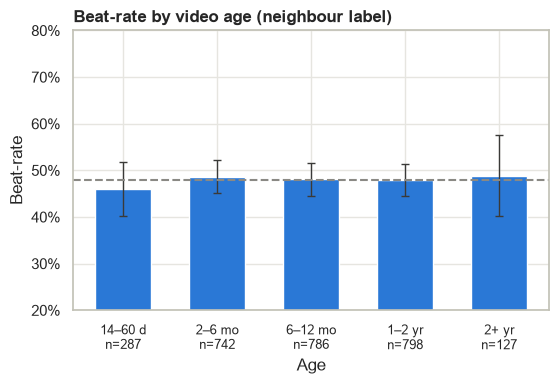

,mean,size,ci
age_bucket,,,
14–60 d,0.460,287,0.058
2–6 mo,0.487,742,0.036
6–12 mo,0.481,786,0.035
1–2 yr,0.480,798,0.035
2+ yr,0.488,127,0.087


In [16]:
shorts["age_bucket"] = pd.cut(shorts["age_days"], bins=[13, 60, 180, 365, 730, 10_000],
                              labels=["14–60 d", "2–6 mo", "6–12 mo", "1–2 yr", "2+ yr"])
beat_rate_chart(shorts, "age_bucket", "Beat-rate by video age (neighbour label)", xlabel="Age",
                filename="beat_rate_age.png")

In [17]:
# The same check within each creator (share of Shorts beating the median, by age)
shorts.pivot_table(index="creator", columns="age_bucket", values="beat",
                   aggfunc="mean", observed=False).round(2)

age_bucket,14–60 d,2–6 mo,6–12 mo,1–2 yr,2+ yr
creator,,,,,
Andrew Huberman,0.33,0.50,0.47,0.49,0.55
Bryan Johnson,0.56,0.45,0.45,0.48,0.47
David Perlmutter,0.52,0.50,0.47,NaN,1.00
Eric Berg,0.51,0.48,0.49,0.52,NaN
Gabrielle Lyon,0.45,0.49,0.49,0.48,NaN
Gary Brecka,0.46,0.48,0.50,NaN,NaN
Jessie Inchauspe,0.41,0.56,0.46,0.50,NaN
Louisa Nicola,0.38,0.50,0.47,0.42,NaN
Mark Hyman,0.50,0.44,0.49,NaN,NaN


## 9. Likes & comments (context only)

Post-publish engagement is strongly tied to views, which is why it's **excluded from the model**: it would leak the answer.

In [18]:
print(shorts[["views", "likes", "comments"]].corr(method="spearman").round(2))

          views  likes  comments
views      1.00   0.98      0.94
likes      0.98   1.00      0.95
comments   0.94   0.95      1.00


## 10. Takeaways for modelling

**Data quality**
- 2,740 Shorts, 11 channels, no missing values in anything we'll model on. Classes are near-balanced (48% beat), so accuracy and ROC-AUC are both meaningful, with ROC-AUC as the main metric.
- 48 Shorts reached ≥ 10× their neighbours' median. They're kept: a binary label stops them from dominating.

**The label fix mattered**
- With the first label (channel's overall median), the youngest Shorts beat only 33% of the time and some channels showed strong growth/decline trends. The neighbour label flattens this to 46–49% across ages.
- Several early "findings" disappeared after the fix: hashtags went from −7 to +2 points and "you/your" from +3 to ~0. They were partly artefacts of *when* Shorts were posted. This is a useful lesson to present.
- The very newest Shorts (14–60 days) are still a little lower for some creators (they're still collecting views and use a one-sided window). Small enough to note as a limitation rather than model around.

**Signals worth modelling** (simple one-at-a-time comparisons, so not yet controlling for each other)
| Feature | What we saw | Strength |
|---|---|---|
| Duration | ≤ 30 s: 58% and 91–180 s: 55%, vs 61–90 s: 41% | strongest; intervals clearly separate |
| Number in title | +7 points (n = 530) | clear |
| Question mark | −4 points | borderline |
| Title length | 15+ words lowest (40%) | weak; few long titles |
| Weekday / hour | Tue–Wed lower, Fri–Sat higher; late-night low | weak; overlapping intervals |

**Decisions for notebook 03**
- Features: `duration_sec` (plus buckets), title flags (number, question, length), hook style, topic, claim intensity, `has_person_name` (the biggest outlier is a guest-name clip), publish hour/weekday, TF-IDF.
- Exclude `likes` / `comments` (Spearman ρ ≈ 0.95–0.98 with views: pure leakage), `age_days` (handled by the label), and `creator` / `channel_type`.
- Expect modest performance (AUC ≈ 0.55–0.62): the individual effects are small, which is normal for titles.